# Intel Image Classification Project

In this notebook, different deep learning models were developed and evaluated using the Intel Image Classification dataset. The main goal is to evaluate different architectures in terms of accuracy, generalization performance, and interpretability for scene image classification.

The following steps were conducted throughout this study:

- Exploring the dataset and applying preprocessing steps
- Preparing training, validation, and test datasets
- Applying Data Augmentation techniques
- Building and training a Custom CNN model from scratch
- Training ResNet and EfficientNet-based models using Transfer Learning
- Comparing model accuracy and loss metrics
- Computing Confusion Matrix, Classification Report, and error analysis
- Analyzing misclassified images to interpret model behavior
- Visualizing model attention regions using Grad-CAM

This notebook aims not only to train models, but also to analyze results and evaluate the strengths and weaknesses of different architectures.

In [21]:
import os
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers,Model, models

In [2]:

train_path = Path("data/seg_train")
test_path = Path("data/seg_test")
pred_path = Path("data/seg_pred")

Checking class count and names

In [4]:
classes = sorted([folder.name for folder in train_path.iterdir() if folder.is_dir()])

print(classes)

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


Checking image count per class and verifying class balance

In [5]:
for class_name in classes:
    num_images = len(list((train_path / class_name).glob("*")))
    print(f"{class_name}: {num_images}")

buildings: 2191
forest: 2271
glacier: 2404
mountain: 2512
sea: 2274
street: 2382


In [6]:
train_counts = {}

for class_name in classes:
    train_counts[class_name] = len(
        list((train_path / class_name).glob("*"))
    )

test_counts = {}

for class_name in classes:
    test_counts[class_name] = len(
        list((test_path / class_name).glob("*"))
    )

print(train_counts)

print(test_counts)

{'buildings': 2191, 'forest': 2271, 'glacier': 2404, 'mountain': 2512, 'sea': 2274, 'street': 2382}
{'buildings': 437, 'forest': 474, 'glacier': 553, 'mountain': 525, 'sea': 510, 'street': 501}


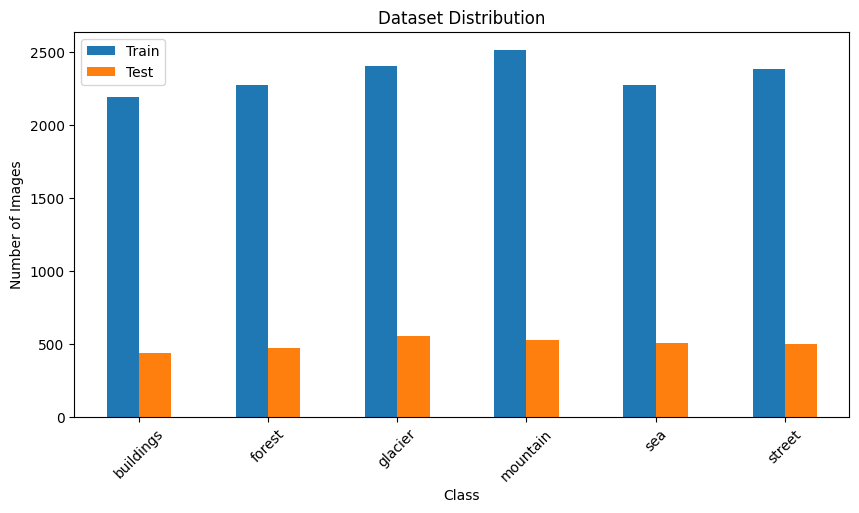

In [7]:
distribution_df = pd.DataFrame({
    "Train": train_counts,
    "Test": test_counts
})
distribution_df.plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Dataset Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.show()


The dataset is well-balanced; no class weighting, oversampling, or undersampling is needed

Display sample images

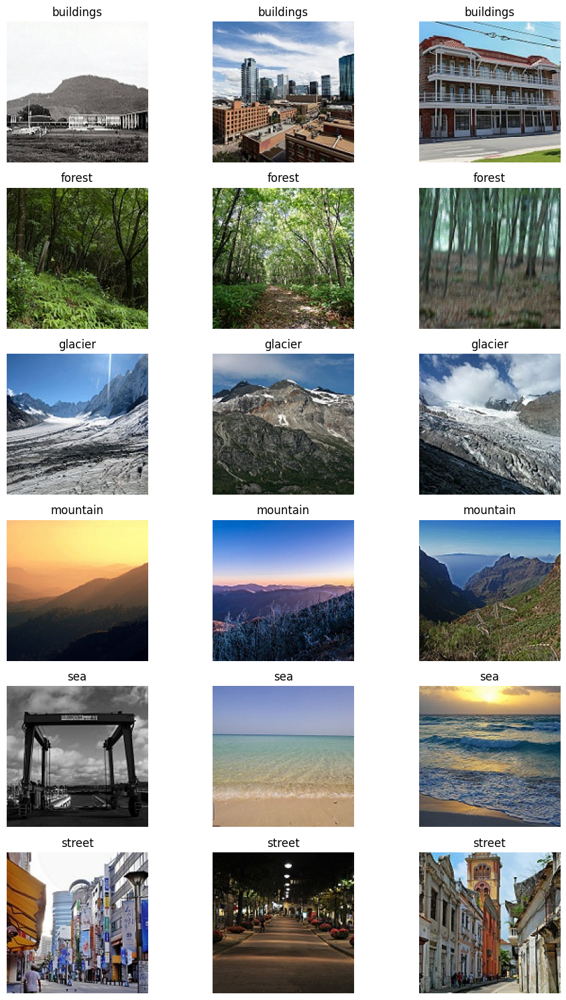

In [8]:


fig, axes = plt.subplots(len(classes), 3, figsize=(10, 15))

for row, class_name in enumerate(classes):

    image_paths = sorted((train_path / class_name).glob("*"))[:3]

    for col, image_path in enumerate(image_paths):

        image = Image.open(image_path)

        axes[row, col].imshow(image)
        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

Checking image dimensions and uniformity

In [9]:
image_sizes = []

for class_name in classes:

    image_paths = list((train_path / class_name).glob("*"))

    for image_path in image_paths:

        image = Image.open(image_path)

        image_sizes.append(image.size)

unique_sizes = set(image_sizes)


In [10]:
from collections import Counter

size_counts = Counter(image_sizes)

size_df = (
    pd.DataFrame(size_counts.items(), columns=["Size", "Count"])
    .sort_values("Count", ascending=False),
    
)

size_df

(          Size  Count
 0   (150, 150)  13986
 2   (150, 113)      7
 6   (150, 135)      3
 10  (150, 111)      3
 3   (150, 108)      2
 7   (150, 136)      2
 13  (150, 143)      2
 14  (150, 146)      2
 17  (150, 123)      2
 16  (150, 142)      2
 15  (150, 134)      2
 22  (150, 144)      2
 5   (150, 115)      1
 1   (150, 124)      1
 4   (150, 133)      1
 11  (150, 120)      1
 12  (150, 149)      1
 8   (150, 110)      1
 9   (150, 105)      1
 18  (150, 119)      1
 19  (150, 102)      1
 20   (150, 76)      1
 21   (150, 97)      1
 23  (150, 103)      1
 24  (150, 100)      1
 25  (150, 141)      1
 26  (150, 145)      1
 27   (150, 81)      1
 28  (150, 147)      1
 29  (150, 131)      1
 30  (150, 140)      1,)

Verifying color mode (RGB)

In [11]:
image_modes = []

for class_name in classes:

    image_paths = list((train_path / class_name).glob("*"))

    for image_path in image_paths:

        image = Image.open(image_path)

        image_modes.append(image.mode)

print(set(image_modes))

{'RGB'}


Checking for corrupted images

In [12]:
corrupted_images = []

for class_name in classes:

    image_paths = list((train_path / class_name).glob("*"))

    for image_path in image_paths:

        try:
            image = Image.open(image_path)
            image.verify()

        except Exception:
            corrupted_images.append(image_path)

print(f"Number of corrupted images: {len(corrupted_images)}")

Number of corrupted images: 0


In [27]:
SEED = 42
BATCH_SIZE = 32
IMAGE_SIZE = (150, 150)

Splitting into training and validation sets

In [28]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)
# shuffle=False so that true labels and predictions are compared in the same order

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.


In [15]:
print(train_dataset.class_names)
print(test_dataset.class_names)

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [16]:
# Checking batch shape and range
for images, labels in train_dataset.take(1):
    print("batch",images.shape)
    print("label batch",labels.shape)
    print("pixel range",images.numpy().min(),images.numpy().max())

batch (32, 150, 150, 3)
label batch (32,)
pixel range 0.0 255.0


3 = RGB
Pixel values are between 0-255 as they are not normalized yet

data augmentation

In [5]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(
        height_factor=0.08,
        width_factor=0.08
    ),
    tf.keras.layers.RandomContrast(0.10)
], name="data_augmentation")

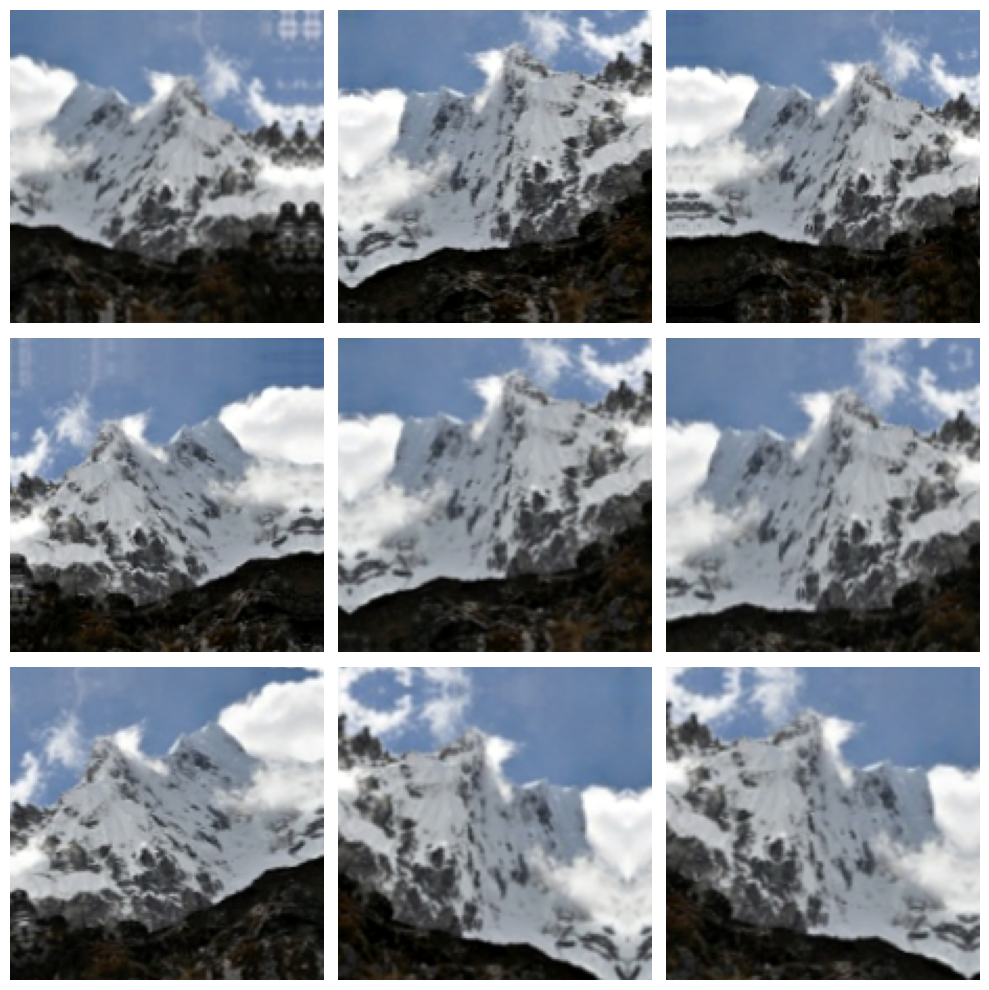

In [18]:
plt.figure(figsize=(10, 10))

for images, labels in train_dataset.take(1):
    sample_image = images[1]

    for i in range(9):
        augmented_image = data_augmentation(
            tf.expand_dims(sample_image, axis=0),
            training=True
        )

        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(
            tf.cast(
                tf.squeeze(augmented_image),
                tf.uint8
            )
        )
        plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(
    buffer_size=AUTOTUNE
)

validation_dataset = validation_dataset.prefetch(
    buffer_size=AUTOTUNE
)

test_dataset = test_dataset.prefetch(
    buffer_size=AUTOTUNE
)
# prefetch: prepares the next batch in the background while the model trains on the current batch

CNN architecture layout:     
input-
data augmentation-
normalization-
conv1-
conv2-
conv3-
feature map -> vector conversion => flatten ile-
dense layer-
dropout-
output => with softmax activation

In [20]:
inputs=tf.keras.layers.Input(shape=(150,150,3))

In [21]:
X = data_augmentation(inputs)

In [22]:
# Normalization layer placement
X = tf.keras.layers.Rescaling(1.0 / 255)(X)

In [23]:
X= tf.keras.layers.Conv2D(filters=32,kernel_size=(3,3),padding="same",activation="relu")(X)

filters=32: Extracting 32 distinct feature maps

Sliding 3x3 kernel over spatial dimensions

Padding prevents spatial shrinkage after convolution

In [24]:
X=tf.keras.layers.MaxPooling2D(pool_size=(2,2))(X)

Feature map resized to 75x75

In [25]:
X=tf.keras.layers.Conv2D(filters=64,kernel_size=(3,3),padding="same",activation="relu")(X)


X=tf.keras.layers.MaxPooling2D(pool_size=(2,2))(X)

In [26]:
X=tf.keras.layers.Conv2D(filters=128,kernel_size=(3,3),padding="same",activation="relu")(X)

X=tf.keras.layers.MaxPooling2D(pool_size=(3,3))(X)

Current feature map dimension is 18x18x128

Feature maps are extracted; transitioning to classification head

Flattening before dense layers

In [27]:
X=tf.keras.layers.Flatten()(X)

In [28]:
X=tf.keras.layers.Dense(units=128,activation="relu")(X)

# Stabilizes training
X= tf.keras.layers.BatchNormalization()(X)

X=tf.keras.layers.Dropout(0.5)(X)

In [29]:
outputs= tf.keras.layers.Dense(units=6, activation="softmax")(X)

In [30]:
model= tf.keras.Model(inputs=inputs,outputs=outputs)

In [31]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,359,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,453,958 (9.36 MB)

 Trainable params: 2,453,702 (9.36 MB)

 Non-trainable params: 256 (1.00 KB)

Model defined; compiling and training next

In [32]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss= tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

In [33]:
train_image_count = sum(images.shape[0] for images, labels in train_dataset)
val_image_count = sum(images.shape[0] for images, labels in validation_dataset)

print("Train image count:", train_image_count)
print("Validation image count:", val_image_count)

Train image count: 11228
Validation image count: 2806


In [34]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=20,
    callbacks=[early_stopping]
)

Epoch 1/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 100s 271ms/step - accuracy: 0.5107 - loss: 1.3170 - val_accuracy: 0.3931 - val_loss: 2.0906
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 97s 277ms/step - accuracy: 0.6638 - loss: 0.9156 - val_accuracy: 0.7085 - val_loss: 0.8220
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 138s 392ms/step - accuracy: 0.7047 - loss: 0.8121 - val_accuracy: 0.6796 - val_loss: 0.8738
Epoch 4/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 141s 402ms/step - accuracy: 0.7236 - loss: 0.7609 - val_accuracy: 0.7830 - val_loss: 0.6113
Epoch 5/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 140s 398ms/step - accuracy: 0.7455 - loss: 0.7056 - val_accuracy: 0.7313 - val_loss: 0.7470
Epoch 6/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 147s 420ms/step - accuracy: 0.7638 - loss: 0.6620 - val_accuracy: 0.8029 - val_loss: 0.5537
Epoch 7/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 158s 451ms/step - accuracy: 0.7671 - loss: 0.6582 - val_accuracy: 0.6942 - val_loss: 0.8661
Epoch 8/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 176s 376ms/step - accuracy: 0.7800 - 

In [35]:
model.save("custom_cnn_model.keras")

In [36]:

cnn_model = model
cnn_history = history

# Since EarlyStopping monitors val_loss, we select the best epoch based on minimum val_loss.
cnn_best_epoch_index = int(np.argmin(cnn_history.history["val_loss"]))

cnn_results = {
    "Model": "Custom CNN",
    "Best Epoch": cnn_best_epoch_index + 1,
    "Train Accuracy": cnn_history.history["accuracy"][cnn_best_epoch_index],
    "Validation Accuracy": cnn_history.history["val_accuracy"][cnn_best_epoch_index],
    "Train Loss": cnn_history.history["loss"][cnn_best_epoch_index],
    "Validation Loss": cnn_history.history["val_loss"][cnn_best_epoch_index]
}

print("CNN best results:")
for metric, value in cnn_results.items():
    if isinstance(value, (float, np.floating)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")


CNN best results:
Model: Custom CNN
Best Epoch: 6
Train Accuracy: 0.7672
Validation Accuracy: 0.8029
Train Loss: 0.6579
Validation Loss: 0.5537


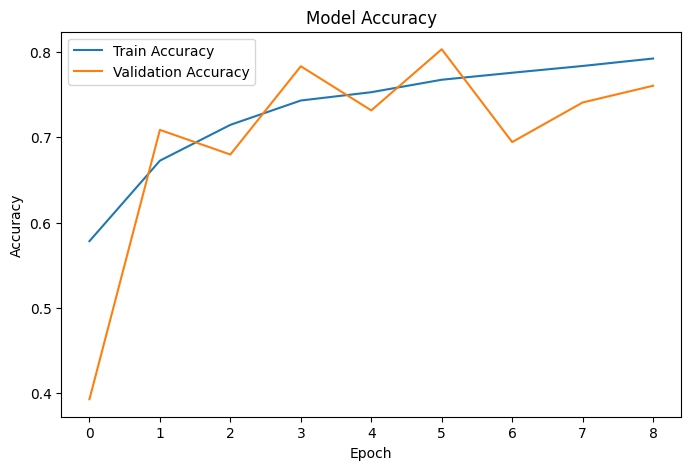

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

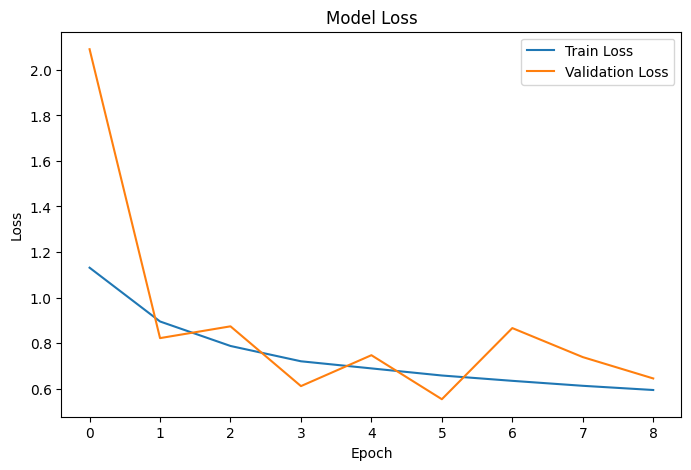

In [38]:
plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [39]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

 2/94 ━━━━━━━━━━━━━━━━━━━━ 9s 101ms/step - accuracy: 0.7734 - loss: 0.5262 

94/94 ━━━━━━━━━━━━━━━━━━━━ 9s 98ms/step - accuracy: 0.8054 - loss: 0.5505
Test Loss: 0.5582677125930786
Test Accuracy: 0.8059999942779541


In [40]:

y_true_cnn = []
y_pred_cnn = []
cnn_predictions=[]
for images, labels in test_dataset:
    predictions = model.predict(images, verbose=0)

    cnn_predictions.extend(predictions)
    y_true_cnn.extend(labels.numpy())
    y_pred_cnn.extend(np.argmax(predictions, axis=1))

y_true_cnn = np.array(y_true_cnn)
y_pred_cnn = np.array(y_pred_cnn)

In [41]:
from sklearn.metrics import classification_report

class_names = [
    "buildings",
    "forest",
    "glacier",
    "mountain",
    "sea",
    "street"
]

print(
    classification_report(
        y_true_cnn,
        y_pred_cnn,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

   buildings       0.77      0.81      0.79       437
      forest       0.97      0.92      0.95       474
     glacier       0.82      0.69      0.75       553
    mountain       0.83      0.64      0.73       525
         sea       0.70      0.90      0.78       510
      street       0.80      0.89      0.84       501

    accuracy                           0.81      3000
   macro avg       0.81      0.81      0.81      3000
weighted avg       0.81      0.81      0.80      3000



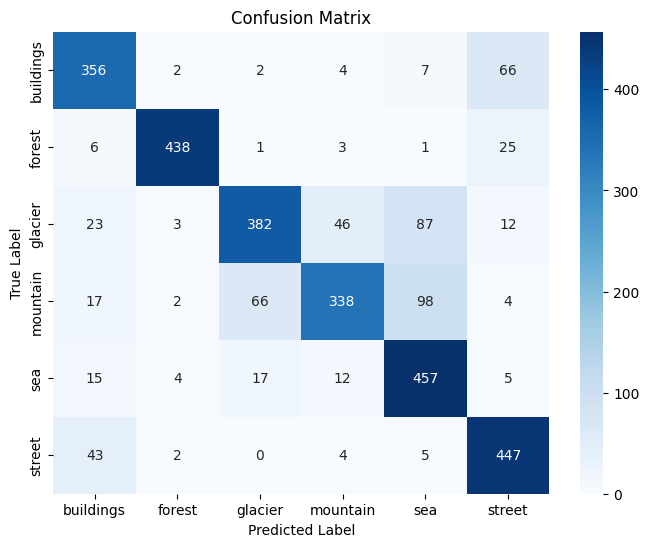

In [43]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true_cnn, y_pred_cnn)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")

plt.show()

hata analizi

In [44]:
correct_images_cnn = []
correct_true_cnn = []
correct_pred_cnn = []
correct_probs_cnn = []

for images, labels in test_dataset:
    predictions = cnn_model.predict(images, verbose=0)

    pred_labels = np.argmax(predictions, axis=1)

    for i in range(len(labels)):
        if pred_labels[i] == labels[i]:
            correct_images_cnn.append(images[i].numpy().astype("uint8"))
            correct_true_cnn.append(labels[i].numpy())
            correct_pred_cnn.append(pred_labels[i])
            correct_probs_cnn.append(np.max(predictions[i]))

correct_images_cnn = np.array(correct_images_cnn)
correct_true_cnn = np.array(correct_true_cnn)
correct_pred_cnn = np.array(correct_pred_cnn)
correct_probs_cnn = np.array(correct_probs_cnn)

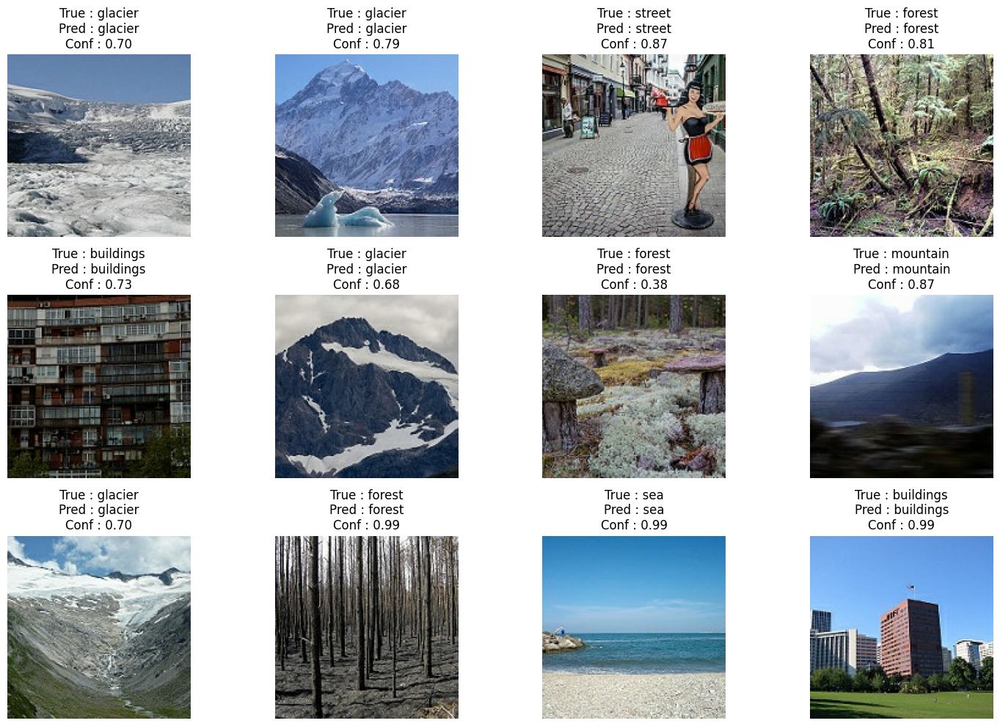

In [45]:
plt.figure(figsize=(15,10))

indices = np.random.choice(len(correct_images_cnn),12,replace=False)

for i,idx in enumerate(indices):

    plt.subplot(3,4,i+1)

    plt.imshow(correct_images_cnn[idx])

    plt.title(
        f"True : {class_names[correct_true_cnn[idx]]}\n"
        f"Pred : {class_names[correct_pred_cnn[idx]]}\n"
        f"Conf : {correct_probs_cnn[idx]:.2f}"
    )

    plt.axis("off")

plt.tight_layout()

plt.show()

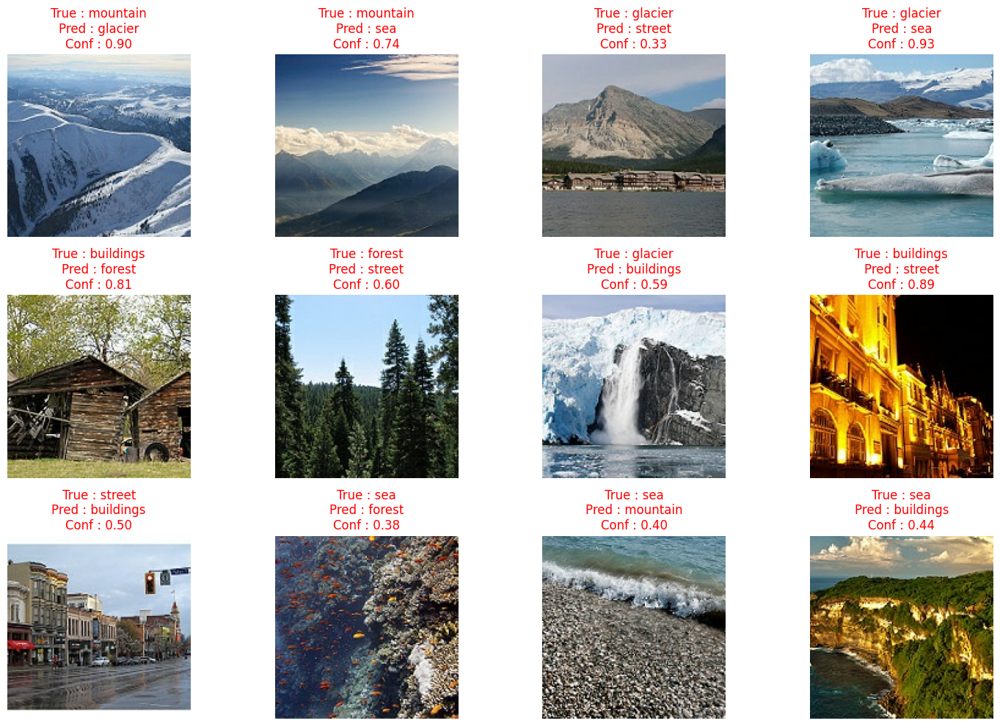

In [46]:
wrong_images_cnn = []
wrong_true_cnn = []
wrong_pred_cnn = []
wrong_probs_cnn = []

for images, labels in test_dataset:

    predictions = cnn_model.predict(images, verbose=0)

    pred_labels = np.argmax(predictions, axis=1)

    for i in range(len(labels)):

        if pred_labels[i] != labels[i]:

            wrong_images_cnn.append(images[i].numpy().astype("uint8"))
            wrong_true_cnn.append(labels[i].numpy())
            wrong_pred_cnn.append(pred_labels[i])
            wrong_probs_cnn.append(np.max(predictions[i]))

wrong_images_cnn = np.array(wrong_images_cnn)
wrong_true_cnn = np.array(wrong_true_cnn)
wrong_pred_cnn = np.array(wrong_pred_cnn)
wrong_probs_cnn = np.array(wrong_probs_cnn)

plt.figure(figsize=(15,10))

indices = np.random.choice(
    len(wrong_images_cnn),
    12,
    replace=False
)

for i, idx in enumerate(indices):

    plt.subplot(3,4,i+1)

    plt.imshow(wrong_images_cnn[idx])

    plt.title(
        f"True : {class_names[wrong_true_cnn[idx]]}\n"
        f"Pred : {class_names[wrong_pred_cnn[idx]]}\n"
        f"Conf : {wrong_probs_cnn[idx]:.2f}",
        color="red"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

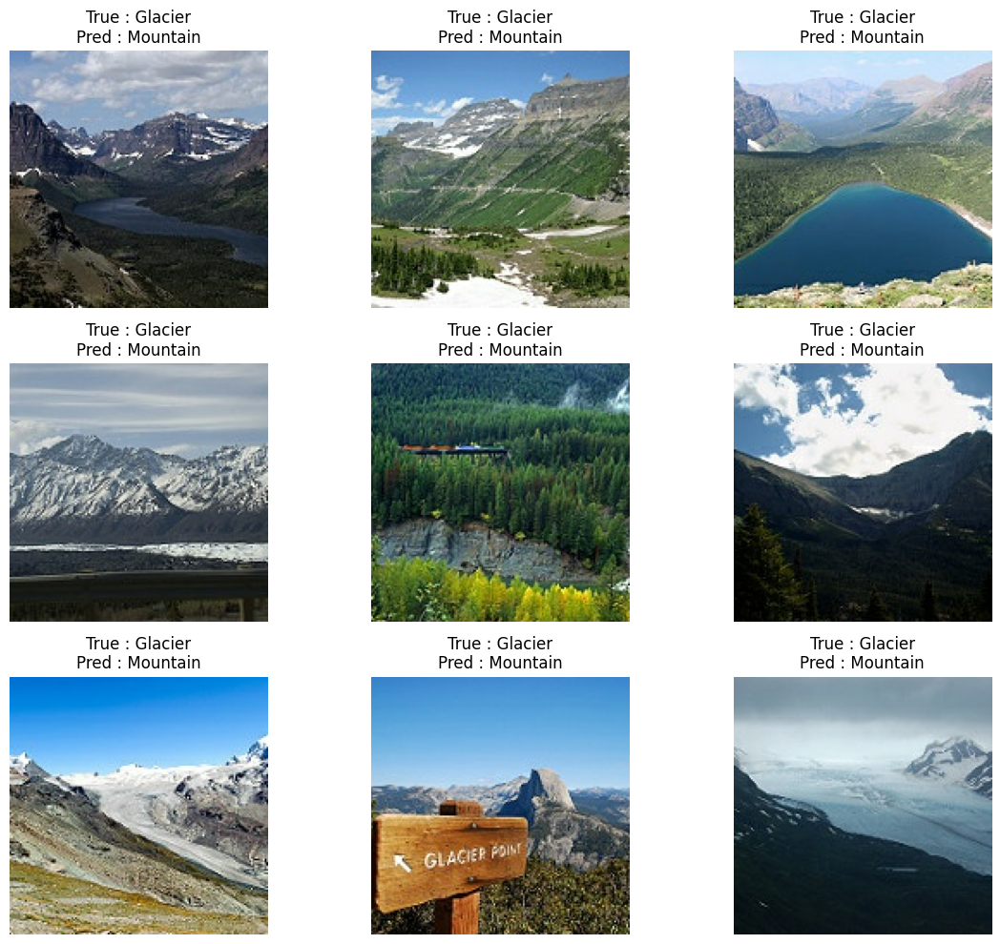

In [47]:
glacier = class_names.index("glacier")
mountain = class_names.index("mountain")

selected_cnn = []

for i in range(len(wrong_true_cnn)):

    if wrong_true_cnn[i] == glacier and wrong_pred_cnn[i] == mountain:
        selected_cnn.append(i)

plt.figure(figsize=(12,10))

for j,idx in enumerate(selected_cnn[:9]):

    plt.subplot(3,3,j+1)

    plt.imshow(wrong_images_cnn[idx])

    plt.title(
        f"True : Glacier\nPred : Mountain"
    )

    plt.axis("off")

plt.tight_layout()

plt.show()

In [48]:
predictions_cnn = model.predict(test_dataset)

predicted_classes = np.argmax(predictions_cnn, axis=1)

true_classes = np.concatenate(
    [y for x, y in test_dataset],
    axis=0
)

wrong_indices = np.where(predicted_classes != true_classes)[0]

print("Total misclassified predictions:", len(wrong_indices))

94/94 ━━━━━━━━━━━━━━━━━━━━ 7s 75ms/step
Total misclassified predictions: 582


resnet50 transfer learning

In [49]:
from tensorflow.keras.applications import ResNet50

resnet= ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(150,150,3)
)

resnet.trainable=False
# Freeze learned weights during initial feature-extraction training

Model architecture with Functional API

In [50]:
from tensorflow.keras.applications.resnet50 import preprocess_input

inputs=tf.keras.layers.Input(shape=(150,150,3))

X=data_augmentation(inputs)

X=tf.keras.layers.Lambda(preprocess_input)(X)

X= resnet(X,training=False)

X= tf.keras.layers.GlobalAveragePooling2D()(X)

X=tf.keras.layers.Dropout(0.2)(X)

outputs=tf.keras.layers.Dense(6,activation="softmax")(X)

resnet_model=tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="resnet50"
)

resnet_model.summary()

Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 5, 5, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │        12,294 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,600,006 (90.03 MB)

 Trainable params: 12,294 (48.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [51]:
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]

)

early_stopping= tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [52]:
history_resnet= resnet_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=30,
    callbacks=[early_stopping]
)

Epoch 1/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 668s 2s/step - accuracy: 0.4810 - loss: 1.4322 - val_accuracy: 0.8610 - val_loss: 0.4233
Epoch 2/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 794s 2s/step - accuracy: 0.8169 - loss: 0.5086 - val_accuracy: 0.8860 - val_loss: 0.3257
Epoch 3/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 602s 2s/step - accuracy: 0.8542 - loss: 0.4064 - val_accuracy: 0.8902 - val_loss: 0.2927
Epoch 4/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 372s 1s/step - accuracy: 0.8650 - loss: 0.3705 - val_accuracy: 0.8956 - val_loss: 0.2737
Epoch 5/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 503s 1s/step - accuracy: 0.8703 - loss: 0.3433 - val_accuracy: 0.9009 - val_loss: 0.2627
Epoch 6/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 516s 1s/step - accuracy: 0.8820 - loss: 0.3208 - val_accuracy: 0.9070 - val_loss: 0.2562
Epoch 7/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 575s 2s/step - accuracy: 0.8884 - loss: 0.3033 - val_accuracy: 0.9084 - val_loss: 0.2479
Epoch 8/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 833s 2s/step - accuracy: 0.8879 - loss: 0.2995 - val_accu

In [53]:
resnet_model.save("resnet_transfer_learning_model.keras")

In [54]:
resnet_best_epoch_index = int(np.argmin(history_resnet.history["val_loss"]))

resnet_results = {
    "Model": "ResNET50",
    "Best Epoch": resnet_best_epoch_index + 1,
    "Train Accuracy": history_resnet.history["accuracy"][resnet_best_epoch_index],
    "Validation Accuracy": history_resnet.history["val_accuracy"][resnet_best_epoch_index],
    "Train Loss": history_resnet.history["loss"][resnet_best_epoch_index],
    "Validation Loss":history_resnet.history["val_loss"][resnet_best_epoch_index]
}

print("ResNET50 best results:")
for metric, value in resnet_results.items():
    if isinstance(value, (float, np.floating)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")


ResNET50 best results:
Model: ResNET50
Best Epoch: 16
Train Accuracy: 0.9034
Validation Accuracy: 0.9198
Train Loss: 0.2542
Validation Loss: 0.2215


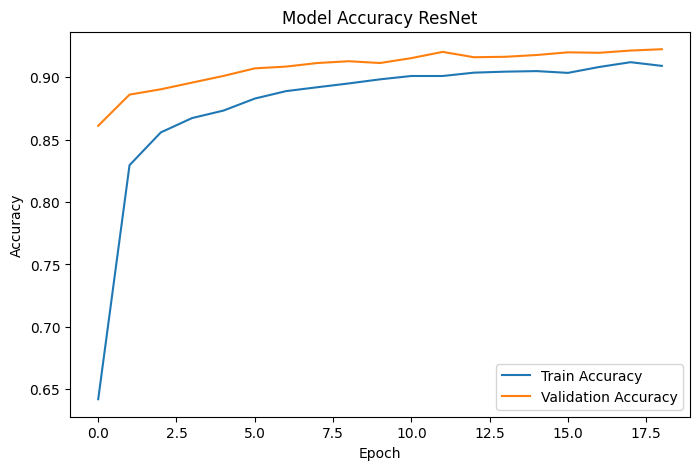

In [55]:


plt.figure(figsize=(8,5))

plt.plot(history_resnet.history["accuracy"], label="Train Accuracy")
plt.plot(history_resnet.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy ResNet")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

Data augmentation and dropout make training images more challenging.

Therefore, validation performance can appear slightly better.

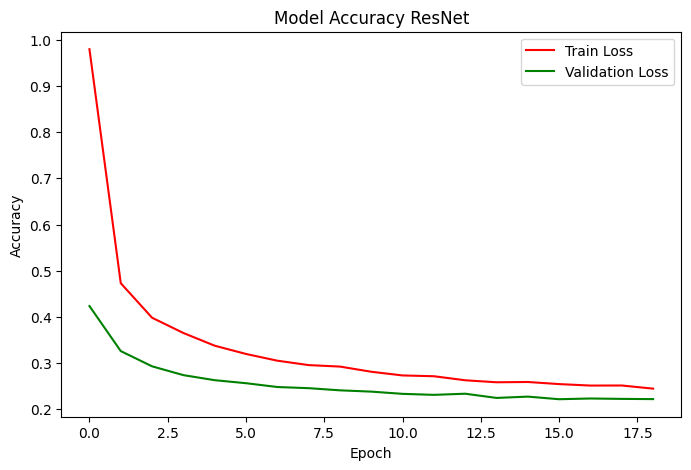

In [57]:

plt.figure(figsize=(8,5))

plt.plot(history_resnet.history["loss"], label="Train Loss",color="r")
plt.plot(history_resnet.history["val_loss"], label="Validation Loss",color="g")

plt.title("Model Accuracy ResNet")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

In [58]:
test_loss, test_accuracy = resnet_model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 83s 885ms/step - accuracy: 0.9177 - loss: 0.2214
Test Loss: 0.23878072202205658
Test Accuracy: 0.9116666913032532


In [59]:
y_true_resnet = []
y_pred_resnet = []
resnet_predictions = []

for images, labels in test_dataset:
    predictions = resnet_model.predict(images, verbose=0)

    resnet_predictions.extend(predictions)
    y_true_resnet.extend(labels.numpy())
    y_pred_resnet.extend(np.argmax(predictions, axis=1))

resnet_predictions = np.array(resnet_predictions)
y_true_resnet = np.array(y_true_resnet)
y_pred_resnet = np.array(y_pred_resnet)

In [61]:
class_names = [
    "buildings",
    "forest",
    "glacier",
    "mountain",
    "sea",
    "street"
]

print(
    classification_report(
        y_true_resnet,
        y_pred_resnet,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

   buildings       0.93      0.92      0.93       437
      forest       0.98      1.00      0.99       474
     glacier       0.86      0.82      0.84       553
    mountain       0.87      0.82      0.84       525
         sea       0.91      0.98      0.94       510
      street       0.93      0.94      0.93       501

    accuracy                           0.91      3000
   macro avg       0.91      0.91      0.91      3000
weighted avg       0.91      0.91      0.91      3000



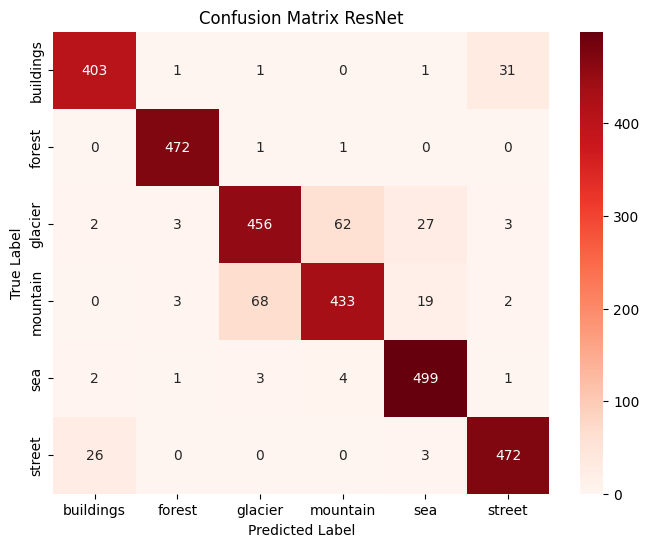

In [60]:

cm = confusion_matrix(y_true_resnet, y_pred_resnet)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Reds",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix ResNet")

plt.show()

efficientNet

In [7]:
from tensorflow.keras.applications import EfficientNetB0

efficientnet=EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(150,150,3)
)

efficientnet.trainable=False

In [8]:
inputs= tf.keras.layers.Input(shape=(150,150,3))

X=data_augmentation(inputs)

X=efficientnet(X,training=False)

X=tf.keras.layers.GlobalAveragePooling2D()(X)

X=tf.keras.layers.Dropout(0.2)(X)

outputs=tf.keras.layers.Dense(
    6,
    activation="softmax"
)(X)

efficientnet_model=tf.keras.Model(inputs=inputs,
                                outputs=outputs,
                                name="efficientnet")

efficientnet_model.summary()

Model: "efficientnet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 5, 5, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,057,257 (15.48 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [9]:

efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]

)

early_stopping= tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [10]:
history_efficientnet= efficientnet_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=30,
    callbacks=[early_stopping]
)

Epoch 1/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 135s 368ms/step - accuracy: 0.4584 - loss: 1.4586 - val_accuracy: 0.8286 - val_loss: 0.6802
Epoch 2/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 164s 467ms/step - accuracy: 0.8047 - loss: 0.6866 - val_accuracy: 0.8781 - val_loss: 0.4480
Epoch 3/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 210s 597ms/step - accuracy: 0.8448 - loss: 0.5067 - val_accuracy: 0.8934 - val_loss: 0.3666
Epoch 4/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 184s 524ms/step - accuracy: 0.8546 - loss: 0.4465 - val_accuracy: 0.8967 - val_loss: 0.3266
Epoch 5/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 249s 707ms/step - accuracy: 0.8654 - loss: 0.4028 - val_accuracy: 0.9013 - val_loss: 0.3031
Epoch 6/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 245s 699ms/step - accuracy: 0.8734 - loss: 0.3691 - val_accuracy: 0.9038 - val_loss: 0.2872
Epoch 7/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 189s 489ms/step - accuracy: 0.8738 - loss: 0.3620 - val_accuracy: 0.9073 - val_loss: 0.2749
Epoch 8/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 155s 442ms/step - accuracy: 0.8744 -

In [11]:
efficientnet_model.save("efficientnet_transfer_learning_model.keras")

In [12]:
efficientnet_best_epoch_index = int(np.argmin(history_efficientnet.history["val_loss"]))
efficientnet_results = {
    "Model": "EfficientNet",
    "Best Epoch": efficientnet_best_epoch_index + 1,
    "Train Accuracy": history_efficientnet.history["accuracy"][efficientnet_best_epoch_index],
    "Validation Accuracy": history_efficientnet.history["val_accuracy"][efficientnet_best_epoch_index],
    "Train Loss": history_efficientnet.history["loss"][efficientnet_best_epoch_index],
    "Validation Loss":history_efficientnet.history["val_loss"][efficientnet_best_epoch_index]
}

print("EfficientNet best results:")
for metric, value in efficientnet_results.items():
    if isinstance(value, (float, np.floating)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")


EfficientNet best results:
Model: EfficientNet
Best Epoch: 28
Train Accuracy: 0.8995
Validation Accuracy: 0.9134
Train Loss: 0.2784
Validation Loss: 0.2251


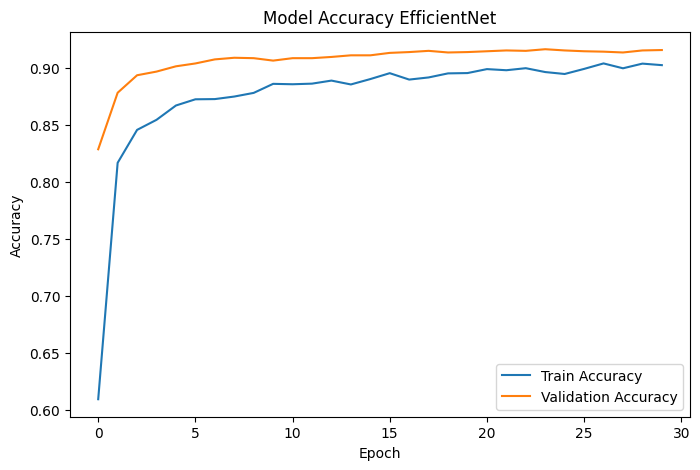

In [13]:

plt.figure(figsize=(8,5))

plt.plot(history_efficientnet.history["accuracy"], label="Train Accuracy")
plt.plot(history_efficientnet.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy EfficientNet")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

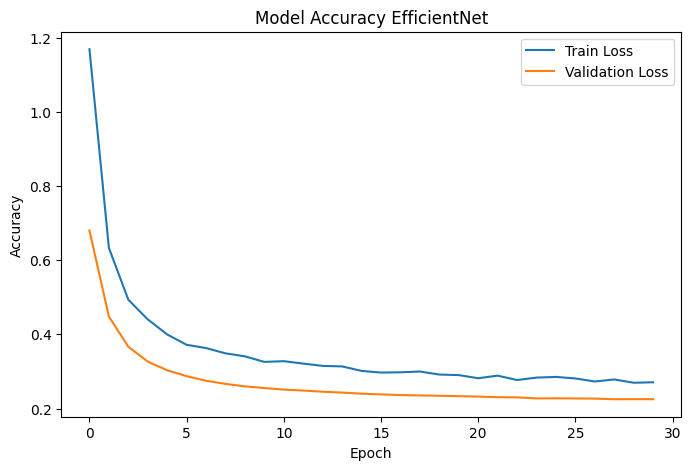

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history_efficientnet.history["loss"], label="Train Loss")
plt.plot(history_efficientnet.history["val_loss"], label="Validation Loss")

plt.title("Model Accuracy EfficientNet")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

In [15]:
test_loss, test_accuracy = efficientnet_model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 21s 223ms/step - accuracy: 0.9021 - loss: 0.2661
Test Loss: 0.250745564699173
Test Accuracy: 0.9100000262260437


In [18]:
from sklearn.metrics import classification_report
y_true_efficientnet = []
y_pred_efficientnet = []
efficientnet_predictions = []

for images, labels in test_dataset:
    predictions = efficientnet_model.predict(images, verbose=0)

    efficientnet_predictions.extend(predictions)
    y_true_efficientnet.extend(labels.numpy())
    y_pred_efficientnet.extend(np.argmax(predictions, axis=1))

efficientnet_predictions = np.array(efficientnet_predictions)
y_true_efficientnet = np.array(y_true_efficientnet)
y_pred_efficientnet= np.array(y_pred_efficientnet)

class_names = [
    "buildings",
    "forest",
    "glacier",
    "mountain",
    "sea",
    "street"
]

print(
    classification_report(
        y_true_efficientnet,
        y_pred_efficientnet,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

   buildings       0.94      0.88      0.91       437
      forest       0.99      1.00      1.00       474
     glacier       0.85      0.84      0.85       553
    mountain       0.87      0.83      0.85       525
         sea       0.92      0.97      0.94       510
      street       0.90      0.95      0.92       501

    accuracy                           0.91      3000
   macro avg       0.91      0.91      0.91      3000
weighted avg       0.91      0.91      0.91      3000



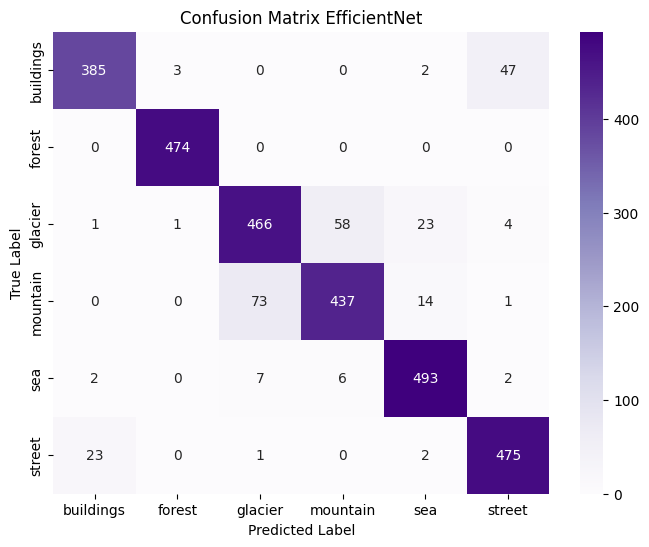

In [20]:

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true_efficientnet, y_pred_efficientnet)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix EfficientNet")

plt.show()

efficientNet fine-tuning

In [27]:
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.resnet50 import preprocess_input

In [28]:
cnn_loaded_model=load_model("custom_cnn_model.keras")


In [29]:
resnet_transfer_learning_loaded_model = load_model(
    "resnet_transfer_learning_model.keras",
    custom_objects={"preprocess_input": preprocess_input}
)

prediction

In [30]:
import glob
import tensorflow as tf

image_paths = glob.glob("data/seg_pred/*.jpg")

print("Number of images:", len(image_paths))

Number of images: 7301


In [31]:
IMG_SIZE = (150, 150)

def load_pred_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)

    return image

In [32]:
pred_dataset = tf.data.Dataset.from_tensor_slices(image_paths)

pred_dataset = pred_dataset.map(
    load_pred_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

pred_dataset = pred_dataset.batch(32)
pred_dataset = pred_dataset.prefetch(tf.data.AUTOTUNE)

In [33]:
predictions_cnn = cnn_loaded_model.predict(pred_dataset)

predicted_classes_cnn = tf.argmax(
    predictions_cnn,
    axis=1
).numpy()

confidence_cnn = tf.reduce_max(
    predictions_cnn,
    axis=1
).numpy()

229/229 ━━━━━━━━━━━━━━━━━━━━ 18s 78ms/step


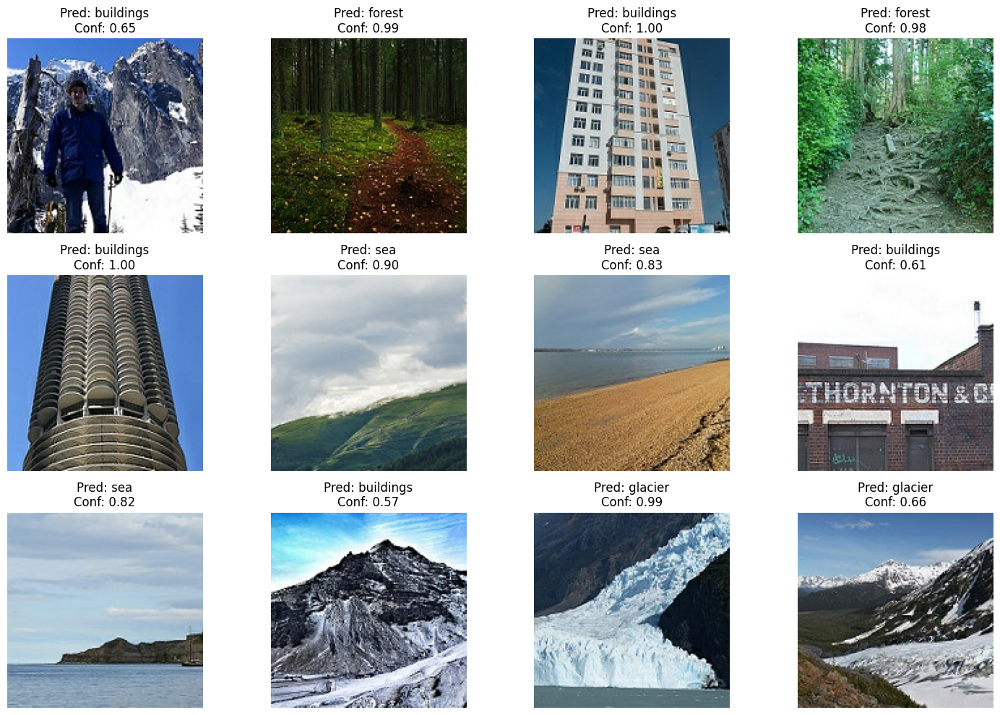

In [34]:
import numpy as np
import matplotlib.pyplot as plt

class_names = [
    "buildings",
    "forest",
    "glacier",
    "mountain",
    "sea",
    "street"
]

indices = np.random.choice(
    len(image_paths),
    size=12,
    replace=False
)

plt.figure(figsize=(15, 10))

for i, idx in enumerate(indices):

    image = load_pred_image(image_paths[idx]).numpy()

    plt.subplot(3, 4, i + 1)
    plt.imshow(image.astype("uint8"))

    plt.title(
        f"Pred: {class_names[predicted_classes_cnn[idx]]}\n"
        f"Conf: {confidence_cnn[idx]:.2f}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [35]:
predictions_cnn = cnn_loaded_model.predict(pred_dataset)
predictions_resnet = resnet_transfer_learning_loaded_model.predict(pred_dataset)
predictions_efficientnet = efficientnet_model.predict(pred_dataset)

pred_cnn = np.argmax(predictions_cnn, axis=1)
pred_resnet = np.argmax(predictions_resnet, axis=1)
pred_efficientnet = np.argmax(predictions_efficientnet, axis=1)



conf_cnn = np.max(predictions_cnn, axis=1)
conf_resnet = np.max(predictions_resnet, axis=1)
conf_efficientnet = np.max(predictions_efficientnet, axis=1)

229/229 ━━━━━━━━━━━━━━━━━━━━ 19s 83ms/step
229/229 ━━━━━━━━━━━━━━━━━━━━ 177s 765ms/step
229/229 ━━━━━━━━━━━━━━━━━━━━ 50s 218ms/step


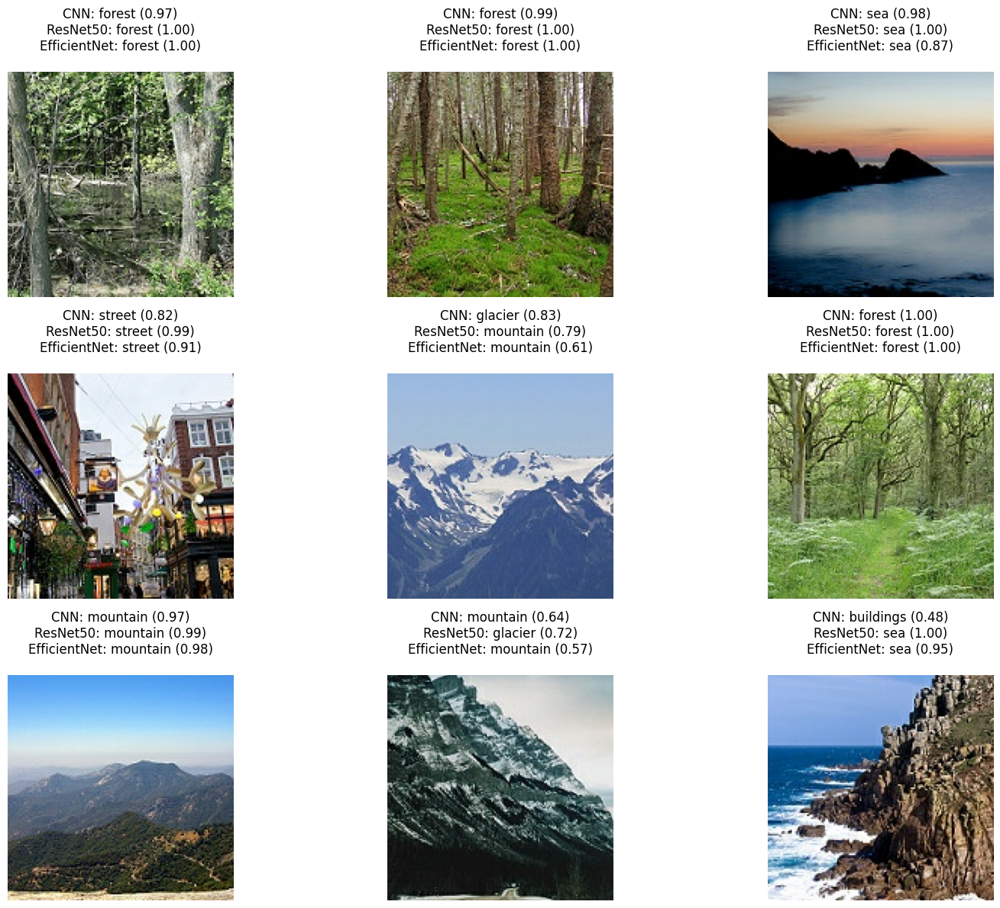

In [36]:
indices = np.random.choice(
    len(image_paths),
    size=9,
    replace=False
)

plt.figure(figsize=(16, 12))

for i, idx in enumerate(indices):

    image = load_pred_image(image_paths[idx]).numpy()

    plt.subplot(3, 3, i + 1)
    plt.imshow(image.astype("uint8"))

    plt.title(
        f"CNN: {class_names[pred_cnn[idx]]} ({conf_cnn[idx]:.2f})\n"
        f"ResNet50: {class_names[pred_resnet[idx]]} ({conf_resnet[idx]:.2f})\n"
        f"EfficientNet: {class_names[pred_efficientnet[idx]]} ({conf_efficientnet[idx]:.2f})\n"
                
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [37]:
import glob
import random
import matplotlib.cm as cm

In [ ]:
image_paths = glob.glob("data/seg_pred/*.jpg")

print("Number of images:", len(image_paths))

Number of images: 7301


In [39]:
class_names = [
    "buildings",
    "forest",
    "glacier",
    "mountain",
    "sea",
    "street"
]

model = resnet_transfer_learning_loaded_model

resnet_base = None

for layer in model.layers:
    if isinstance(layer, tf.keras.Model):
        if "resnet" in layer.name.lower():
            resnet_base = layer
            break

if resnet_base is None:
    raise ValueError("ResNet50 base model could not be found.")

print("Found base model:", resnet_base.name)

Bulunan model: resnet50


In [40]:
last_conv_layer_name = "conv5_block3_out"

last_conv_layer = resnet_base.get_layer(last_conv_layer_name)

print("Grad-CAM layer:", last_conv_layer.name)

Grad-CAM layer: conv5_block3_out


In [41]:
def prepare_image(image_path):
    image = tf.keras.utils.load_img(
        image_path,
        target_size=(150, 150)
    )

    image = tf.keras.utils.img_to_array(image)

    image_batch = np.expand_dims(image, axis=0)

    return image, image_batch

In [42]:
def make_gradcam_heatmap(
    image_batch,
    full_model,
    resnet_base,
    last_conv_layer_name="conv5_block3_out"
):
    last_conv_layer = resnet_base.get_layer(
        last_conv_layer_name
    )

    conv_model = tf.keras.Model(
        inputs=resnet_base.input,
        outputs=last_conv_layer.output
    )

    resnet_index = full_model.layers.index(resnet_base)

    layers_before_resnet = full_model.layers[:resnet_index]
    layers_after_resnet = full_model.layers[resnet_index + 1:]

    last_conv_index = resnet_base.layers.index(
        last_conv_layer
    )

    with tf.GradientTape() as tape:
        x = tf.cast(image_batch, tf.float32)

        # Layers located before ResNet base in the full model
        for layer in layers_before_resnet:
            if isinstance(layer, tf.keras.layers.InputLayer):
                continue

            x = layer(x, training=False)

        # Final convolution feature map
        conv_outputs = conv_model(
            x,
            training=False
        )

        tape.watch(conv_outputs)

        y = conv_outputs

        # Layers inside ResNet after the target convolution layer
        for layer in resnet_base.layers[last_conv_index + 1:]:
            y = layer(y, training=False)

        # Top classification head layers of the full model
        for layer in layers_after_resnet:
            y = layer(y, training=False)

        predictions = y

        predicted_index = tf.argmax(
            predictions[0]
        )

        predicted_score = predictions[
            :, predicted_index
        ]

    gradients = tape.gradient(
        predicted_score,
        conv_outputs
    )

    if gradients is None:
        raise ValueError(
            "Gradients could not be computed. Model architecture may differ."
        )

    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients,
        axis=-1
    )

    heatmap = tf.maximum(
        heatmap,
        0
    )

    max_value = tf.reduce_max(heatmap)

    if max_value > 0:
        heatmap = heatmap / max_value

    return (
        heatmap.numpy(),
        predictions.numpy(),
        int(predicted_index)
    )

In [43]:
def display_gradcam(
    original_image,
    heatmap,
    predicted_class,
    confidence,
    alpha=0.4
):
    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (150, 150)
    ).numpy().squeeze()

    heatmap_uint8 = np.uint8(
        255 * heatmap_resized
    )

    jet = cm.get_cmap("jet")

    jet_colors = jet(
        np.arange(256)
    )[:, :3]

    colored_heatmap = jet_colors[
        heatmap_uint8
    ]

    colored_heatmap = np.uint8(
        colored_heatmap * 255
    )

    superimposed_image = (
        alpha * colored_heatmap
        + (1 - alpha) * original_image
    )

    superimposed_image = np.clip(
        superimposed_image,
        0,
        255
    ).astype("uint8")

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(original_image.astype("uint8"))
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title("Grad-CAM Heatmap")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(superimposed_image)
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence:.2f}"
    )
    plt.axis("off")

    plt.tight_layout()
    plt.show()

In [46]:
selected_image_path = random.choice(image_paths)

original_image, image_batch = prepare_image(
    selected_image_path
)

heatmap, predictions, predicted_index = make_gradcam_heatmap(
    image_batch=image_batch,
    full_model=model,
    resnet_base=resnet_base,
    last_conv_layer_name="conv5_block3_out"
)

predicted_class = class_names[predicted_index]
confidence = predictions[0][predicted_index]

print("Selected image:", selected_image_path)
print("Prediction:", predicted_class)
print("Confidence:", f"{confidence:.4f}")

Selected image: data/seg_pred\2595.jpg
Prediction: mountain
Confidence: 0.7457


C:\Users\lenovo\AppData\Local\Temp\ipykernel_2832\1203524459.py:17: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


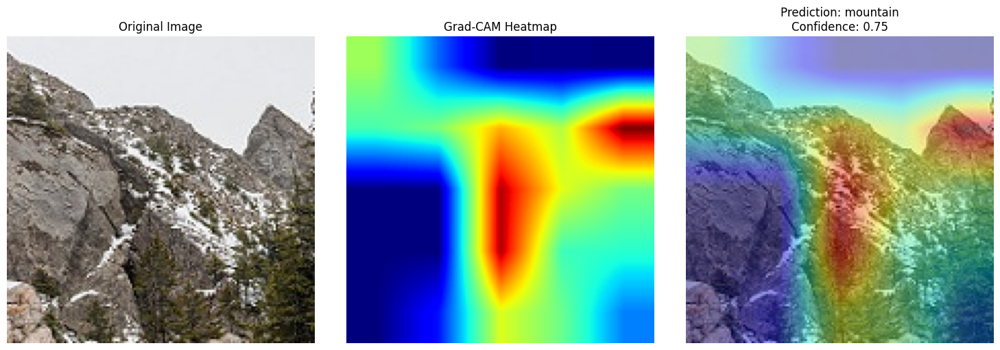

In [47]:
display_gradcam(
    original_image=original_image,
    heatmap=heatmap,
    predicted_class=predicted_class,
    confidence=confidence
)

resnet-34

In [22]:
def residual_block(
    x,
    filters,
    stride=1,
    block_name="residual_block"
):
    shortcut = x

    # Main path: First convolution
    # Stride can be 2 during stage transitions.
    x = layers.Conv2D(
        filters=filters,
        kernel_size=(3, 3),
        strides=stride,
        padding="same",
        use_bias=False,
        name=f"{block_name}_conv1"
    )(x)

    x = layers.BatchNormalization(
        name=f"{block_name}_bn1"
    )(x)

    x = layers.ReLU(
        name=f"{block_name}_relu1"
    )(x)

    # Main path: Second convolution
    # Stride must always be 1 here.
    x = layers.Conv2D(
        filters=filters,
        kernel_size=(3, 3),
        strides=1,
        padding="same",
        use_bias=False,
        name=f"{block_name}_conv2"
    )(x)

    x = layers.BatchNormalization(
        name=f"{block_name}_bn2"
    )(x)

    # If main path and shortcut dimensions differ,
    # project the shortcut path using 1x1 convolution.
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters=filters,
            kernel_size=(1, 1),
            strides=stride,
            padding="same",
            use_bias=False,
            name=f"{block_name}_shortcut_conv"
        )(shortcut)

        shortcut = layers.BatchNormalization(
            name=f"{block_name}_shortcut_bn"
        )(shortcut)

    # F(x) + shortcut
    x = layers.Add(
        name=f"{block_name}_add"
    )([x, shortcut])

    x = layers.ReLU(
        name=f"{block_name}_output_relu"
    )(x)

    return x

In [23]:
def resnet_34_build(input_shape=(150,150,3),num_classes=6):

    inputs=layers.Input(shape=input_shape)

    x=layers.Conv2D(
        filters=64,
        kernel_size=(7,7),
        strides=2,
        padding="same",
        use_bias=False,
        name="conv1"
    )(inputs)

    x=layers.BatchNormalization(name="bn_conv1")(x)

    x=layers.ReLU(name="conv1_relu")(x)

    x=layers.MaxPool2D(
        pool_size=(3,3),
        strides=2,
        padding="same",
        name="pool1"
    )(x)

    #stage 1
    
    x=residual_block(x,filters=64,stride=1,block_name="conv2_block1")

    x=residual_block(x,filters=64,stride=1,block_name="conv2_block2")

    x=residual_block(x,filters=64,stride=1,block_name="conv2_block3")

    #stage 2

    x=residual_block(x,filters=128,stride=2,block_name="conv3_block1")

    x=residual_block(x,filters=128,stride=1,block_name="conv3_block2")

    x=residual_block(x,filters=128,stride=1,block_name="conv3_block3")

    x=residual_block(x,filters=128,stride=1,block_name="conv3_block4")

    #stage 3

    x=residual_block(x,filters=256,stride=2,block_name="conv4_block1")

    x=residual_block(x,filters=256,stride=1,block_name="conv4_block2")
    
    x=residual_block(x,filters=256,stride=1,block_name="conv4_block3")

    x=residual_block(x,filters=256,stride=1,block_name="conv4_block4")

    x=residual_block(x,filters=256,stride=1,block_name="conv4_block5")

    x=residual_block(x,filters=256,stride=1,block_name="conv4_block6")

    #stage 4

    x=residual_block(x,filters=512,stride=2,block_name="conv5_block1")

    x=residual_block(x,filters=512,stride=1,block_name="conv5_block2")

    x=residual_block(x,filters=512,stride=1,block_name="conv5_block3")


    # GlobalAveragePooling eliminates the need for a Flatten layer
    x=layers.GlobalAveragePooling2D(name="global_avg_pool")(x)




    outputs=layers.Dense(num_classes,activation="softmax",name="predictions")(x)

    model=models.Model(inputs=inputs,outputs=outputs,name="ResNet34")

    return model


In [24]:
resnet34_model= resnet_34_build(input_shape=(150,150,3),num_classes=6)

resnet34_model.summary()

Model: "ResNet34"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 150, 150,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1 (Conv2D)      │ (None, 75, 75,    │      9,408 │ input_layer_5[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_conv1            │ (None, 75, 75,    │        256 │ conv1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu (ReLU)   │ (None, 75, 75,    │          0 │ bn_conv1[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 38, 38,    │          0 │ conv1_relu[0][0]  │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_conv1  │ (None, 38, 38,    │     36,864 │ pool1[0][0]       │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_bn1    │ (None, 38, 38,    │        256 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_relu1  │ (None, 38, 38,    │          0 │ conv2_block1_bn1… │
│ (ReLU)              │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_conv2  │ (None, 38, 38,    │     36,864 │ conv2_block1_rel… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_bn2    │ (None, 38, 38,    │        256 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_add    │ (None, 38, 38,    │          0 │ conv2_block1_bn2… │
│ (Add)               │ 64)               │            │ pool1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_outpu… │ (None, 38, 38,    │          0 │ conv2_block1_add… │
│ (ReLU)              │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_conv1  │ (None, 38, 38,    │     36,864 │ conv2_block1_out… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_bn1    │ (None, 38, 38,    │        256 │ conv2_block2_con… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_relu1  │ (None, 38, 38,    │          0 │ conv2_block2_bn1… │
│ (ReLU)              │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_conv2  │ (None, 38, 38,    │     36,864 │ conv2_block2_rel… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_bn2    │ (None, 38, 38,    │        256 │ conv2_block2_con

 Total params: 21,304,774 (81.27 MB)

 Trainable params: 21,287,750 (81.21 MB)

 Non-trainable params: 17,024 (66.50 KB)

In [25]:
resnet34_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),loss=tf.keras.losses.SparseCategoricalCrossentropy(),metrics=["accuracy"])

early_stopping=tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)


In [29]:
history_resnet34=resnet34_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=30,
    callbacks=[early_stopping]
)

Epoch 1/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 990s 3s/step - accuracy: 0.5587 - loss: 1.2029 - val_accuracy: 0.6336 - val_loss: 0.9706
Epoch 2/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 791s 2s/step - accuracy: 0.7565 - loss: 0.6561 - val_accuracy: 0.7776 - val_loss: 0.6437
Epoch 3/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 908s 3s/step - accuracy: 0.8226 - loss: 0.4895 - val_accuracy: 0.7630 - val_loss: 0.7041
Epoch 4/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 868s 2s/step - accuracy: 0.8602 - loss: 0.3988 - val_accuracy: 0.3329 - val_loss: 5.2784
Epoch 5/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 689s 2s/step - accuracy: 0.8965 - loss: 0.2999 - val_accuracy: 0.6500 - val_loss: 1.5734


In [30]:
resnet34_model.save("handmade_resnet_model.keras")